In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, classification_report,
    precision_recall_curve, confusion_matrix
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "data/raw/creditcard.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/creditcard.csv"):
    CSV_PATH = "../data/raw/creditcard.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 284,807 rows, 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
total_nulls = df_raw.isnull().sum().sum()
dup_count = df_raw.duplicated().sum()
dup_fraud_count = df_raw[df_raw.duplicated()]["Class"].sum()

print(f"Total Missing Values Across All 31 Columns : {total_nulls}")
print(f"Total Exact Duplicate Rows                 : {dup_count:,} ({dup_count / len(df_raw):.2%})")
print(f"Duplicate Rows Belonging to Fraud (Class=1): {dup_fraud_count}")

# Class distribution before deduplication
class_counts = df_raw["Class"].value_counts()
class_pct = df_raw["Class"].value_counts(normalize=True) * 100
display(pd.DataFrame({
    "Label": ["Legitimate (0)", "Fraud (1)"],
    "Raw_Count": [class_counts[0], class_counts[1]],
    "Percentage (%)": [round(class_pct[0], 4), round(class_pct[1], 4)]
}))

Total Missing Values Across All 31 Columns : 0
Total Exact Duplicate Rows                 : 1,081 (0.38%)
Duplicate Rows Belonging to Fraud (Class=1): 19


,Label,Raw_Count,Percentage (%)
0,Legitimate (0),284315,99.8273
1,Fraud (1),492,0.1727


Transaction Amount Statistics by Class:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


Zero-Amount ($0.00) Transactions: 1,825 total | 27 Fraud cases (1.48% fraud rate)

Top 5 Negative Correlations with Fraud (Strongest Fraud Indicators when low):
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
Name: Class, dtype: float64

Top 5 Positive Correlations with Fraud:
V11    0.1549
V4     0.1334
V2     0.0913
V21    0.0404
V19    0.0348
Name: Class, dtype: float64


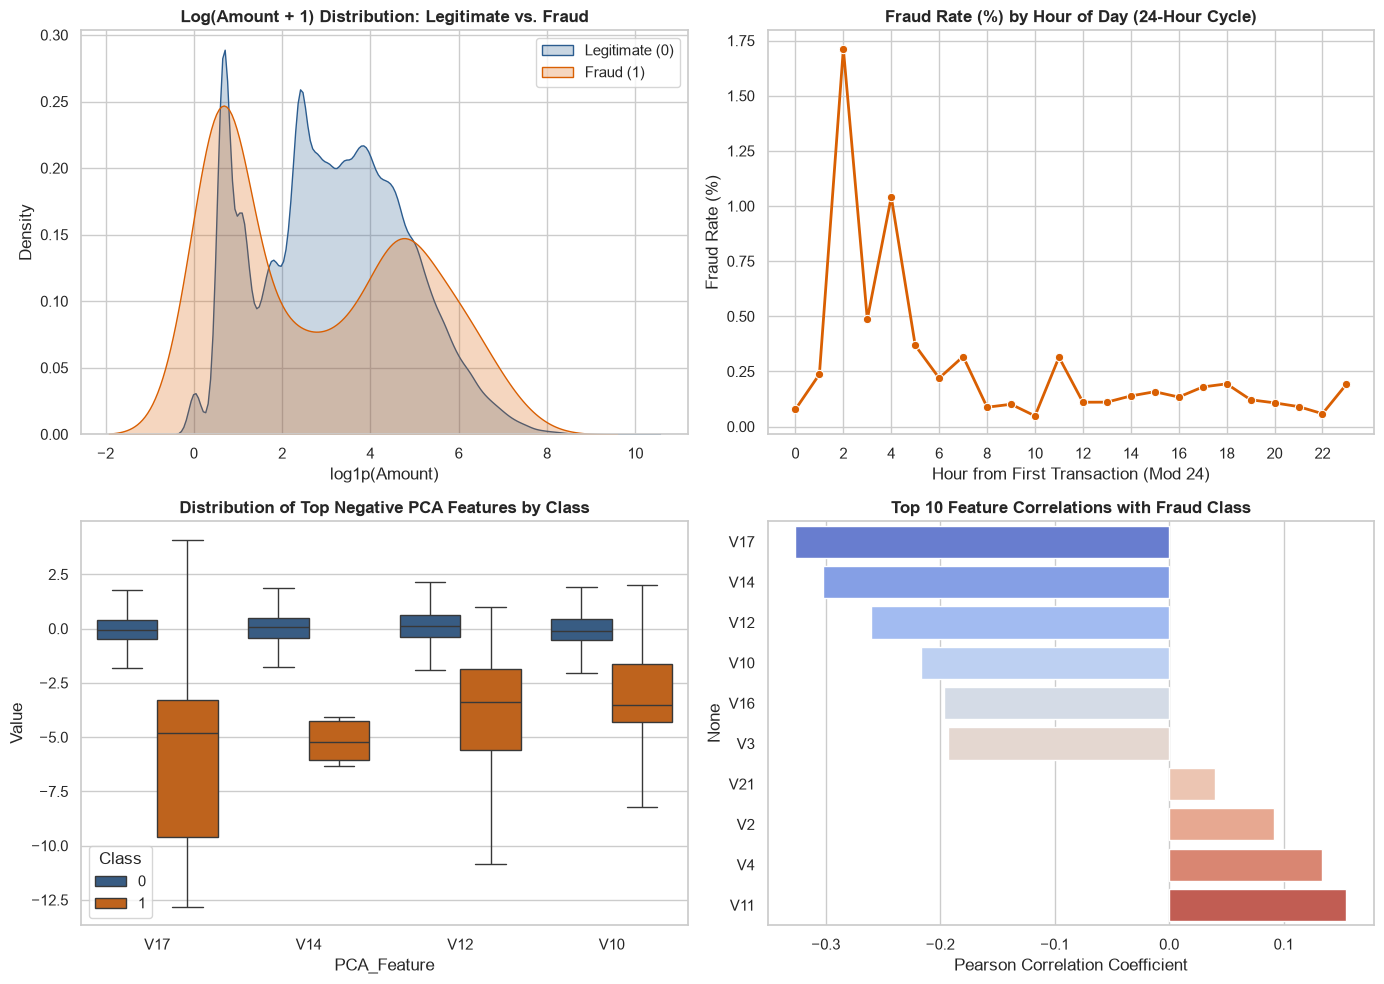

In [5]:
# Compare Amount & Time statistics between Legitimate and Fraud transactions
print("Transaction Amount Statistics by Class:")
display(df_raw.groupby("Class")["Amount"].describe().round(2))

zero_amount_cases = df_raw[df_raw["Amount"] == 0.0]
print(f"Zero-Amount ($0.00) Transactions: {len(zero_amount_cases):,} total | {zero_amount_cases['Class'].sum()} Fraud cases ({zero_amount_cases['Class'].mean():.2%} fraud rate)")

# Top PCA features correlated with Fraud
correlations = df_raw.corr()["Class"].drop("Class").sort_values()
print("\nTop 5 Negative Correlations with Fraud (Strongest Fraud Indicators when low):")
print(correlations.head(5).round(4))
print("\nTop 5 Positive Correlations with Fraud:")
print(correlations.tail(5).sort_values(ascending=False).round(4))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Log-Amount distribution by Class
sns.kdeplot(
    x=np.log1p(df_raw.loc[df_raw["Class"] == 0, "Amount"]),
    label="Legitimate (0)", fill=True, color="#2b5c8f", ax=axes[0, 0]
)
sns.kdeplot(
    x=np.log1p(df_raw.loc[df_raw["Class"] == 1, "Amount"]),
    label="Fraud (1)", fill=True, color="#d95f02", ax=axes[0, 0]
)
axes[0, 0].set_title("Log(Amount + 1) Distribution: Legitimate vs. Fraud", fontweight="bold")
axes[0, 0].set_xlabel("log1p(Amount)")
axes[0, 0].legend()

# 2. Hourly Transaction & Fraud Rate Pattern over 48 Hours
hour_of_day = ((df_raw["Time"] // 3600) % 24).astype(int)
hourly_fraud_rate = df_raw.groupby(hour_of_day)["Class"].mean() * 100
sns.lineplot(x=hourly_fraud_rate.index, y=hourly_fraud_rate.values, marker="o", color="#d95f02", linewidth=2, ax=axes[0, 1])
axes[0, 1].set_title("Fraud Rate (%) by Hour of Day (24-Hour Cycle)", fontweight="bold")
axes[0, 1].set_xlabel("Hour from First Transaction (Mod 24)")
axes[0, 1].set_ylabel("Fraud Rate (%)")
axes[0, 1].set_xticks(range(0, 24, 2))

# 3. Top correlated PCA features (V17, V14, V12, V10) Boxplots
top_pca_cols = ["V17", "V14", "V12", "V10"]
df_melted = df_raw.sample(10000, random_state=42)[top_pca_cols + ["Class"]].melt(id_vars="Class", var_name="PCA_Feature", value_name="Value")
sns.boxplot(data=df_melted, x="PCA_Feature", y="Value", hue="Class", palette=["#2b5c8f", "#d95f02"], showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Top Negative PCA Features by Class", fontweight="bold")

# 4. Top Feature Correlations with Target Class
top_abs_corr = pd.concat([correlations.head(6), correlations.tail(4)])
sns.barplot(x=top_abs_corr.values, y=top_abs_corr.index, palette="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Top 10 Feature Correlations with Fraud Class", fontweight="bold")
axes[1, 1].set_xlabel("Pearson Correlation Coefficient")

plt.tight_layout()
plt.savefig("outputs/eda_fraud_detection.png", dpi=150)
plt.show()

In [6]:
"""
Cleaning Rules Driven by EDA Findings:
1. Remove 1,081 exact duplicate rows (prevents identical transactions from leaking across train and test splits).
2. Retain extreme values in V1-V28 and Amount: in fraud detection, extreme statistical outliers ARE the signal
   (fraud cases heavily populate the tails of V14, V17, and V12). Dropping IQR outliers would erase most fraud cases!
3. Keep zero-amount ($0.00) transactions and flag them during feature engineering, as card-testing fraudsters
   frequently use $0.00 authorization checks to verify stolen cards (1.48% fraud rate vs 0.17% baseline).
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)

print(f"Raw Rows       : {len(df_raw):,} (Fraud: {df_raw['Class'].sum()})")
print(f"Cleaned Rows   : {len(df_clean):,} (Fraud: {df_clean['Class'].sum()} | Fraud Rate: {df_clean['Class'].mean():.4%})")

Raw Rows       : 284,807 (Fraud: 492)
Cleaned Rows   : 283,726 (Fraud: 473 | Fraud Rate: 0.1667%)


In [7]:
df_feat = df_clean.copy()

# 1. Cyclical time-of-day encoding (captures night-time fraud spikes discovered in EDA)
hour_float = (df_feat["Time"] / 3600.0) % 24.0
df_feat["hour_sin"] = np.sin(2 * np.pi * hour_float / 24.0)
df_feat["hour_cos"] = np.cos(2 * np.pi * hour_float / 24.0)

# 2. Log-transformed Amount & Zero-Amount ($0 card-verification probe) indicator
df_feat["log_amount"] = np.log1p(df_feat["Amount"])
df_feat["is_zero_amount"] = (df_feat["Amount"] == 0.0).astype(int)

# 3. Magnitude (L2 Norm) across the top fraud-indicative PCA components (V17, V14, V12, V10, V16)
key_pca = ["V17", "V14", "V12", "V10", "V16"]
df_feat["top_pca_norm"] = np.sqrt((df_feat[key_pca] ** 2).sum(axis=1))

# Drop raw 'Time' after extracting cyclical features
df_feat.drop(columns=["Time"], inplace=True)

X = df_feat.drop(columns=["Class"])
y = df_feat["Class"].values

# Stratified split preserving exact 0.1667% fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Use RobustScaler (median/IQR) on 'Amount' and 'top_pca_norm' so extreme outliers don't skew scaling
scale_cols = ["Amount", "log_amount", "top_pca_norm"]
passthrough_cols = [c for c in X_train.columns if c not in scale_cols]

preprocessor = ColumnTransformer(transformers=[
    ("robust_scaler", RobustScaler(), scale_cols),
    ("passthrough", "passthrough", passthrough_cols),
])

print(f"Train Shape: {X_train.shape} (Frauds: {y_train.sum()}) | Test Shape: {X_test.shape} (Frauds: {y_test.sum()})")

Train Shape: (226980, 34) (Frauds: 378) | Test Shape: (56746, 34) (Frauds: 95)


In [8]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

# Dampened positive weight (sqrt of imbalance ratio) prevents gradient explosion on 1:600 imbalance
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
sqrt_scale_weight = float(np.sqrt(imbalance_ratio))

models = {
    "Logistic Regression (Balanced Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1, random_state=42)),
    ]),
    "XGBoost (Histogram Cost-Sensitive)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=sqrt_scale_weight,
            tree_method="hist",
            eval_metric="aucpr",
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    print(f"\n---> {name}")
    print(f"PR-AUC (Primary) : {pr_auc:.4f} | ROC-AUC : {roc_auc:.4f} | Optimal Threshold : {opt_thresh:.4f}")
    print(f"Confusion Matrix : TP={tp} (Caught Fraud) | FN={fn} (Missed Fraud) | FP={fp} (False Alarm) | TN={tn:,}")
    print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Fraud (1)"]))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_fraud_model.joblib")


---> Logistic Regression (Balanced Baseline)
PR-AUC (Primary) : 0.6838 | ROC-AUC : 0.9663 | Optimal Threshold : 1.0000
Confusion Matrix : TP=72 (Caught Fraud) | FN=23 (Missed Fraud) | FP=10 (False Alarm) | TN=56,641
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00     56651
     Fraud (1)       0.88      0.76      0.81        95

      accuracy                           1.00     56746
     macro avg       0.94      0.88      0.91     56746
  weighted avg       1.00      1.00      1.00     56746


---> XGBoost (Histogram Cost-Sensitive)
PR-AUC (Primary) : 0.8175 | ROC-AUC : 0.9750 | Optimal Threshold : 0.6698
Confusion Matrix : TP=73 (Caught Fraud) | FN=22 (Missed Fraud) | FP=3 (False Alarm) | TN=56,648
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00     56651
     Fraud (1)       0.96      0.77      0.85        95

      accuracy                           1.00     56746
     ma

['outputs/best_fraud_model.joblib']

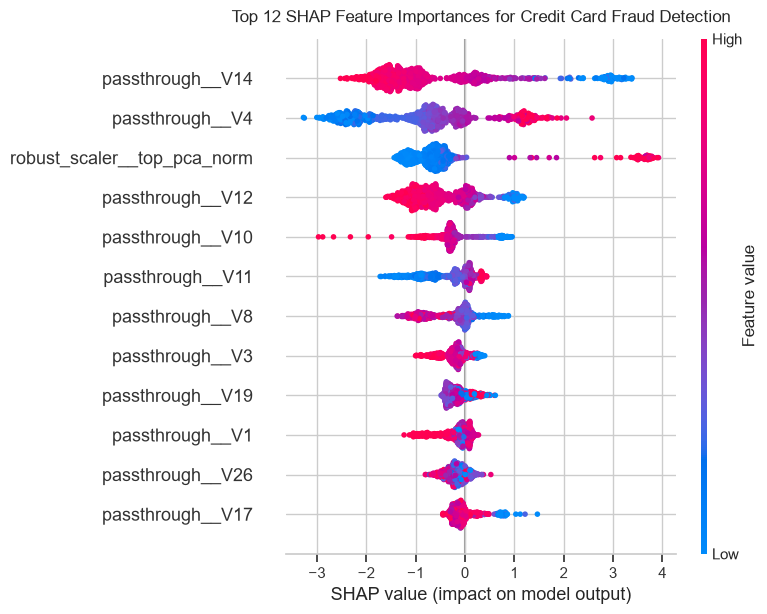

In [9]:
xgb_pipe = models["XGBoost (Histogram Cost-Sensitive)"]

# Sample 1,000 test transactions (including all test fraud cases) for fast local SHAP computation
fraud_indices = np.where(y_test == 1)[0]
legit_indices = np.random.RandomState(42).choice(np.where(y_test == 0)[0], size=900, replace=False)
sample_indices = np.concatenate([fraud_indices, legit_indices])

X_test_sample = X_test.iloc[sample_indices]
X_test_transformed = xgb_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Feature Importances for Credit Card Fraud Detection", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_fraud_detection.png", dpi=150)
plt.show()